## 1) Loading the Taxis Dataset 

In [1]:
import pandas as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the 'taxis' dataset 

df = sns.load_dataset("taxis") 

In [2]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [4]:
df.shape

(6433, 14)

## 2) Handling Missing Values 

In [5]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [6]:
(df.isnull().sum()/len(df))*100

pickup             0.000000
dropoff            0.000000
passengers         0.000000
distance           0.000000
fare               0.000000
tip                0.000000
tolls              0.000000
total              0.000000
color              0.000000
payment            0.683973
pickup_zone        0.404166
dropoff_zone       0.699518
pickup_borough     0.404166
dropoff_borough    0.699518
dtype: float64

In [7]:
df["payment"].fillna(df["payment"].mode()[0])

0       credit card
1              cash
2       credit card
3       credit card
4       credit card
           ...     
6428    credit card
6429    credit card
6430           cash
6431    credit card
6432    credit card
Name: payment, Length: 6433, dtype: str

In [8]:
categorial_columns = [
    "payment","pickup_zone","dropoff_zone","pickup_borough","dropoff_borough"]

for columns in categorial_columns:
    df[columns]= df[columns].fillna(df[columns].mode()[0])

In [9]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [10]:
df.sample(5)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
5529,2019-03-31 19:16:29,2019-03-31 19:28:48,1,2.41,11.0,2.91,0.00,17.46,green,credit card,Brooklyn Heights,Little Italy/NoLiTa,Brooklyn,Manhattan
808,2019-03-01 22:39:03,2019-03-01 22:51:14,1,2.78,11.5,3.06,0.00,18.36,yellow,credit card,Midtown North,Upper West Side North,Manhattan,Manhattan
2777,2019-03-21 14:54:46,2019-03-21 16:06:29,1,20.14,52.0,0.00,5.76,61.06,yellow,cash,JFK Airport,Lenox Hill East,Queens,Manhattan
501,2019-03-21 16:33:14,2019-03-21 17:17:49,1,9.65,33.0,10.76,5.76,53.82,yellow,credit card,Midtown Center,LaGuardia Airport,Manhattan,Queens
5708,2019-03-04 09:42:07,2019-03-04 10:35:59,1,18.60,58.0,0.00,5.76,64.56,green,credit card,Bushwick South,Central Harlem,Brooklyn,Manhattan


## 3) Visualizations using Matplotlib/Pandas Plot: 

#### Line Chart

Text(0, 0.5, 'Fare')

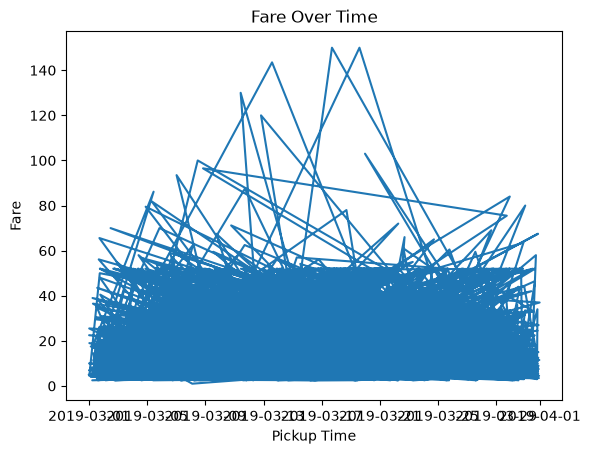

In [11]:
plt.plot(df["pickup"],df["fare"])
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")

#### Bar Chart  

Text(0, 0.5, 'Total Fare')

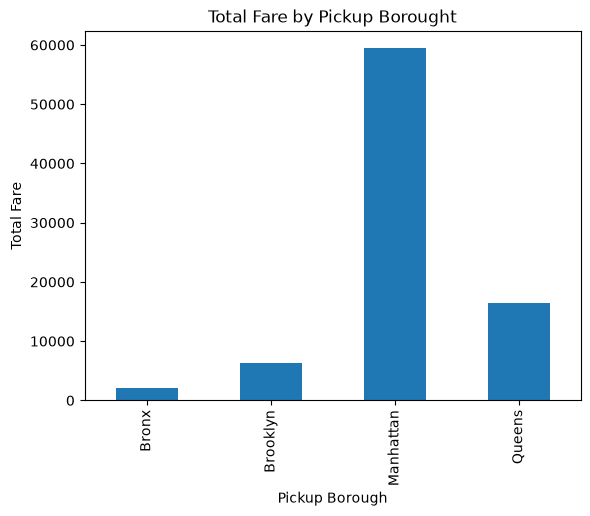

In [12]:
df.groupby("pickup_borough")["fare"].sum().plot(kind="bar")
plt.title("Total Fare by Pickup Borought")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")

#### Pie Chart


<function matplotlib.pyplot.show(close=None, block=None)>

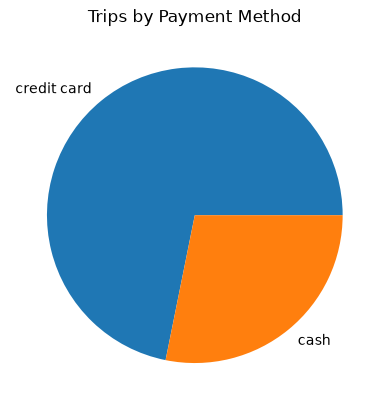

In [13]:
df["payment"].value_counts().plot(kind="pie")
plt.title("Trips by Payment Method")
plt.show

#### Histogram 

<function matplotlib.pyplot.show(close=None, block=None)>

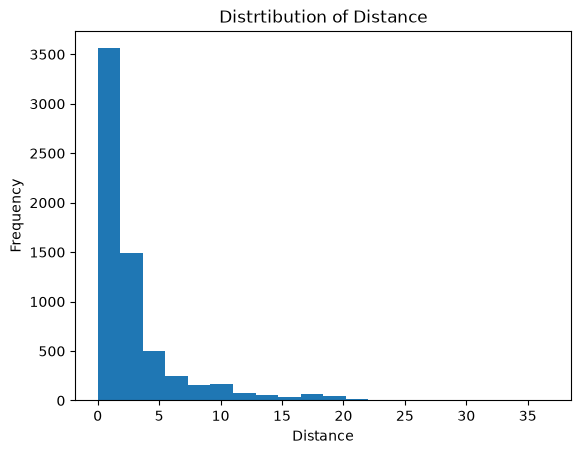

In [14]:
plt.hist(df["distance"],bins = 20)
plt.title("Distrtibution of Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.show

#### Box Plot

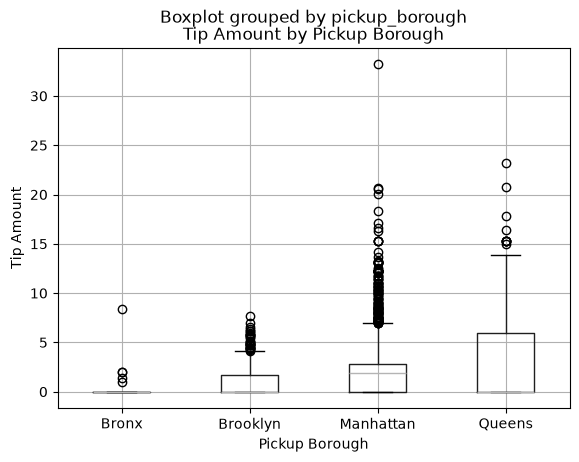

In [15]:
df.boxplot(column ="tip",by="pickup_borough")
plt.title("Tip Amount by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")

plt.show()


## Visualizations using Seaborn: 

#### Count Plot

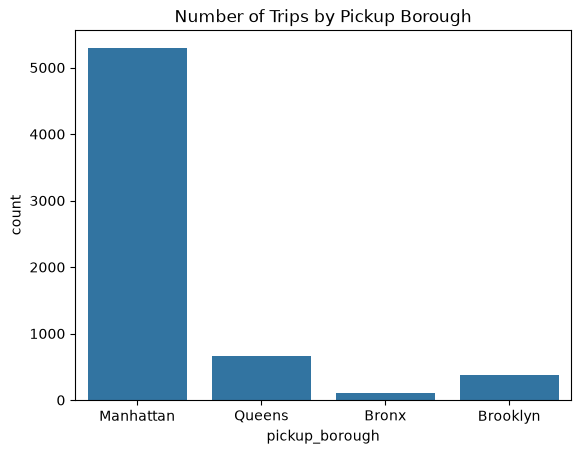

In [16]:
sns.countplot(data=df,x="pickup_borough")
plt.title("Number of Trips by Pickup Borough")
plt.show()

#### Scatter Plot 

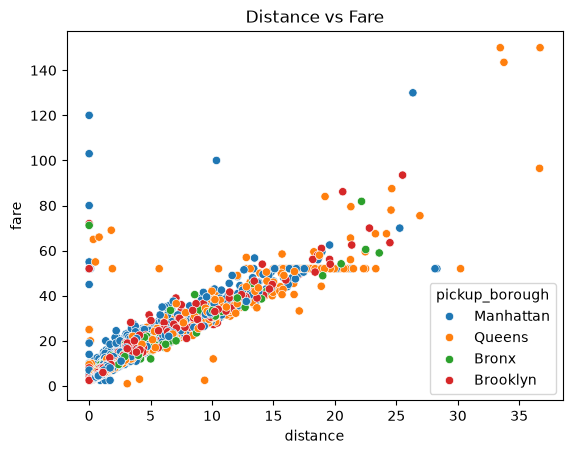

In [17]:
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")
plt.title("Distance vs Fare")
plt.show()

#### Heatmap

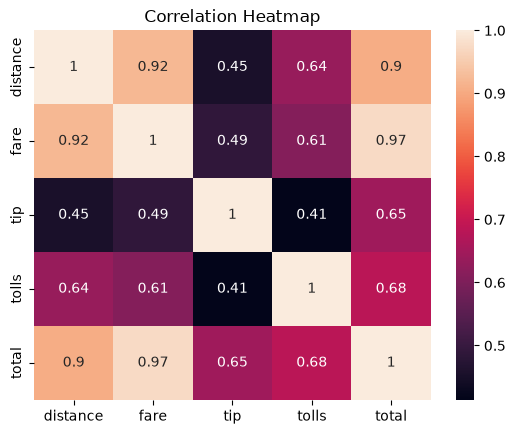

In [18]:
correlation =df[["distance","fare","tip","tolls","total"]].corr()
sns.heatmap(correlation,annot=True)
plt.title("Correlation Heatmap")
plt.show()

####  Pair Plot  

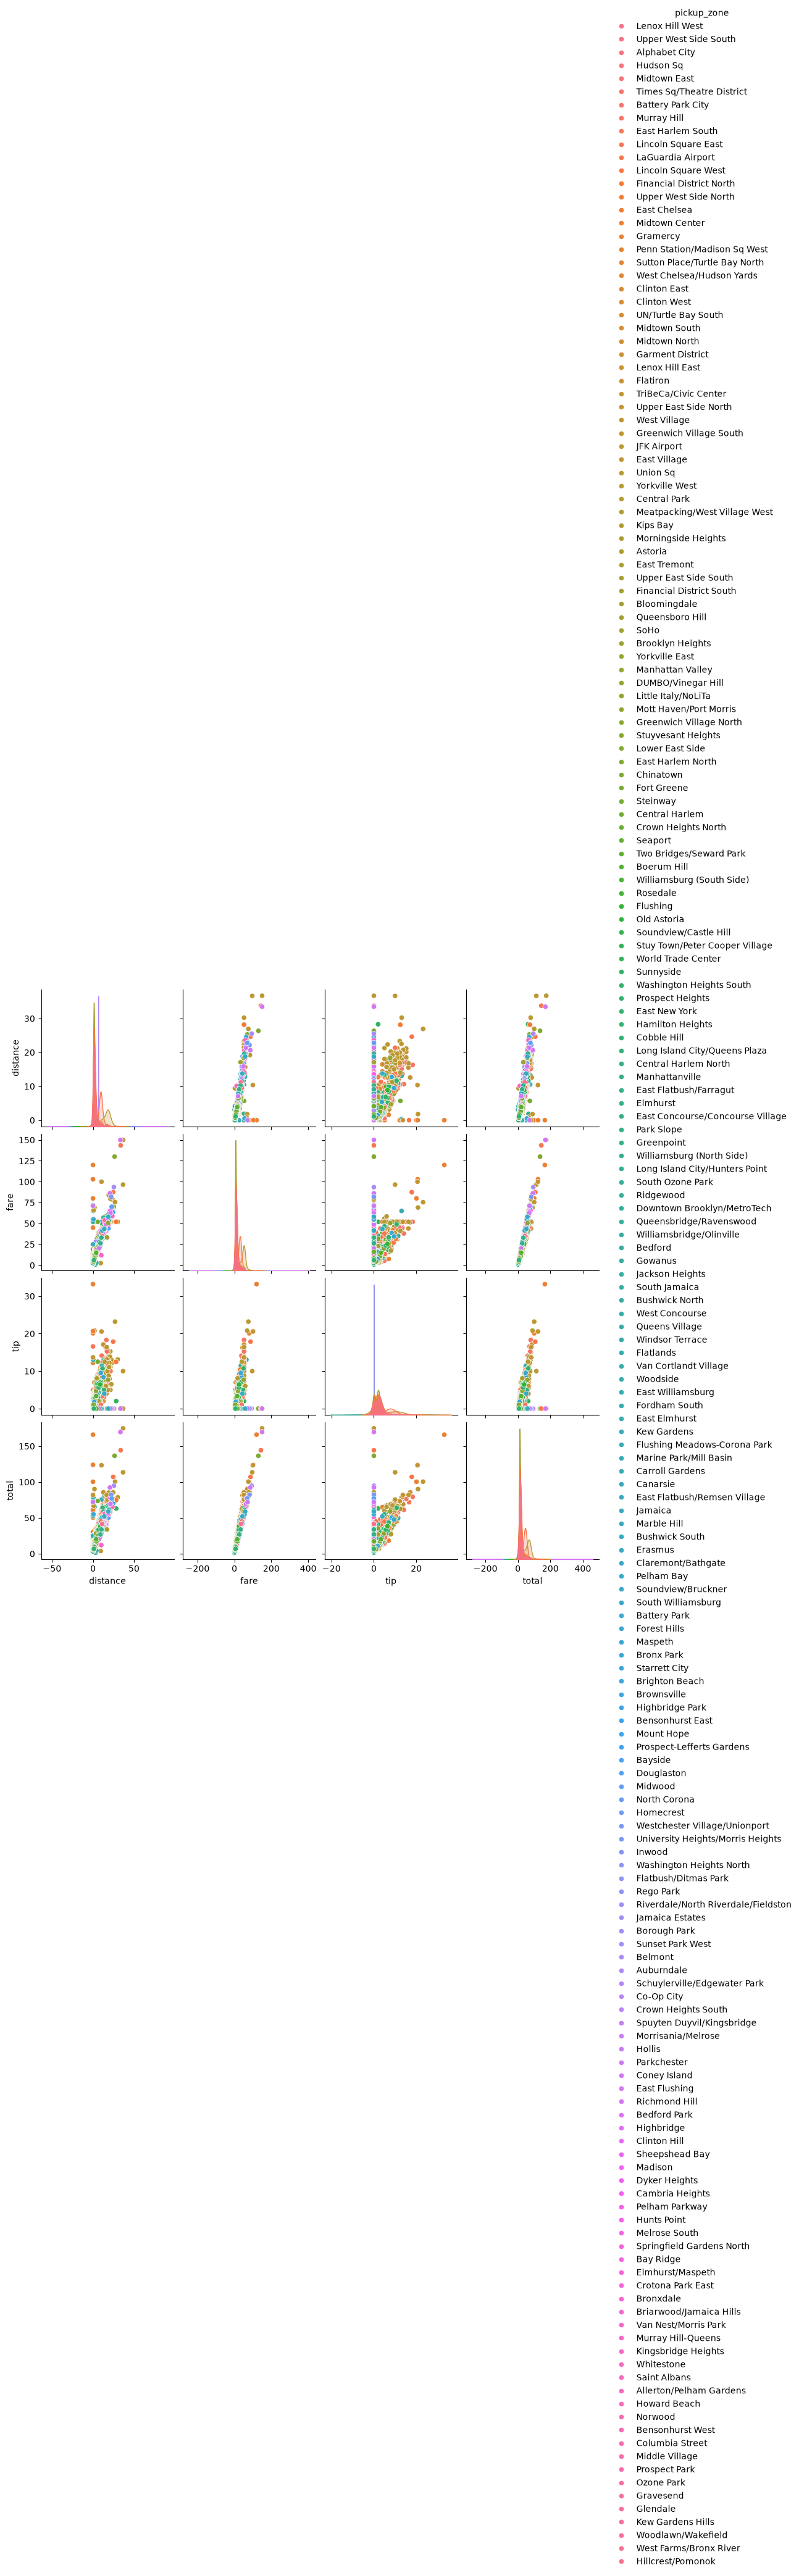

In [19]:
sns.pairplot(df[["distance","fare","tip","total","pickup_zone"]],hue="pickup_zone")
plt.show()

####  Violin Plot

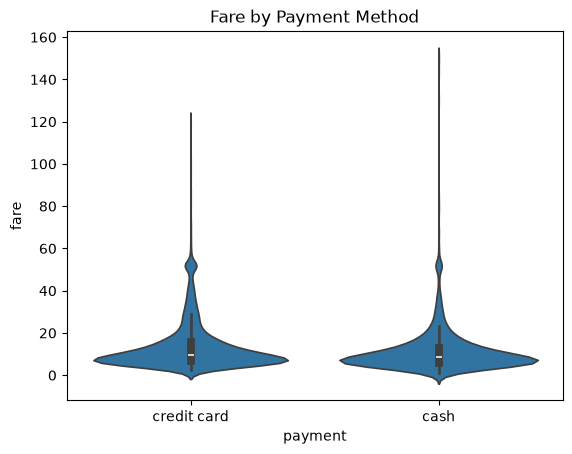

In [20]:
sns.violinplot(data=df,x="payment",y="fare")
plt.title("Fare by Payment Method")
plt.show()